# Lab 3: Decision Tree Classification
## Training, Evaluation & Overfitting — Telco Customer Churn

**Name:** Wajood Ali

**Student ID:** 023-24-0006

**Section:** CS AI B

**GitHub Profile:**https://github.com/wajoodali77-maker/Machine-Learning-Labs

**Kaggle Profile:** https://colab.research.google.com/drive/1wgpMDODF6zUFP-PHHuwGPASwfwdmb7gP#scrollTo=3Ta7RIr-HMyT

**Dataset:** Telco Customer Churn
**Dataset Source:** Kaggle — https://www.kaggle.com/datasets/blastchar/telco-customer-churn

**Duration:** 3 Hours (independent, hands-on)

> This notebook is a **template**, not a tutorial. You already know Python, Pandas, and Decision Tree theory. Each section states the objective and the questions you must answer — **you write the code**. Do not just run code without interpreting it: every table, plot, and metric needs a short written observation.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [1]:
# YOUR CODE HERE
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report




---

## 1. Problem Definition

Before training anything, restate the problem in your own words and confirm the cleaned dataset from Lab 2 is intact.

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.info()`, `df['Churn'].value_counts()`

**Tasks**
1. Load `clean_churn.csv` (or re-run your Lab 2 cleaning). Verify its shape, column dtypes, and that there are no missing values remaining.
2. In 1–2 sentences, restate the ML problem: what exactly are you predicting, and why does it matter to the business?

In [2]:
# Task 1 — load and verify the cleaned dataset
df=pd.read_csv("/content/clean_churn.csv")
print("Shape:", df.shape)
print(df)


Shape: (7043, 20)
      gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0     Female              0     Yes         No       1           No   
1       Male              0      No         No      34          Yes   
2       Male              0      No         No       2          Yes   
3       Male              0      No         No      45           No   
4     Female              0      No         No       2          Yes   
...      ...            ...     ...        ...     ...          ...   
7038    Male              0     Yes        Yes      24          Yes   
7039  Female              0     Yes        Yes      72          Yes   
7040  Female              0     Yes        Yes      11           No   
7041    Male              1     Yes         No       4          Yes   
7042    Male              0      No         No      66          Yes   

         MultipleLines InternetService OnlineSecurity OnlineBackup  \
0     No phone service             DSL             No      

**Answer 2:**
This is a binary classification problem that predicts if a customer will churn (Yes) or stay (No). It helps the business identify customers who may leave and take action to retain them.

---

## 2. Dataset Verification

Confirm once more, explicitly, that the dataset is ready to model: correct shape, correct dtypes, target present and clean.

In [3]:
# Additional verification if needed (dtypes, target check, etc.)
print("Target column present:", "Churn" in df.columns)
print("Target missing values:", df["Churn"].isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print("All columns with missing values:", df.columns[df.isna().any()].tolist())

Target column present: True
Target missing values: 0
Duplicate rows: 22
All columns with missing values: []


---

## 3. Feature/Target Preparation

scikit-learn models require numeric input. Separate your target from your features, then convert any remaining categorical columns into numeric form.

*Concepts/functions you may find useful:* `pd.get_dummies(df, columns=[...])`, `df[col].map({...})`, `df.drop(columns=[...])`, `X.isnull().sum()`, `X.dtypes`

**Tasks**
3. Define `y` as the `Churn` column, encoded as 0/1. Define `X` as the remaining relevant columns — drop any identifier column still present.
4. Convert every remaining categorical column in `X` into numeric form. Briefly justify your choice of encoding method (e.g. one-hot vs. manual mapping).
5. Confirm `X` contains only numeric columns and has no missing values before moving on.

In [4]:
# Task 3 — define y and X
y = df["Churn"].map({"Yes": 1, "No": 0})
X = df.drop(columns=["Churn"])

print("Y shape: ", y.shape)
print("X shape: ", X.shape)
print("Target mapping: yes=1 , no=0")
print(y.value_counts().sort_index())

Y shape:  (7043,)
X shape:  (7043, 19)
Target mapping: yes=1 , no=0
Churn
0    5174
1    1869
Name: count, dtype: int64


In [5]:
from pandas.core.arrays import categorical
# Task 4 — encode categorical columns in X
categorical_cols = X.select_dtypes(include="object").columns.tolist()
X = pd.get_dummies(X, columns=categorical_cols, drop_first=False, dtype=int)

print("Categorical columns encoded:", categorical_cols)
print("Encoded X shape:", X.shape)
print("Number of features after encoding:", X.shape[1])

Categorical columns encoded: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Encoded X shape: (7043, 45)
Number of features after encoding: 45


In [6]:
# Task 5 — confirm X is fully numeric with no missing values
print("All columns numeric:", all(pd.api.types.is_numeric_dtype(dtype) for dtype in X.dtypes))
print("Total missing values in X:", X.isnull().sum().sum())
print("Non-numeric columns:", X.select_dtypes(exclude=np.number).columns.tolist())

All columns numeric: True
Total missing values in X: 0
Non-numeric columns: []


**Answer 4 (encoding method & justification):**

I used one-hot encoding with `pd.get_dummies()` because the categorical variables are nominal or have multiple categories, and one-hot encoding converts them into numeric indicator columns without incorrectly imposing an order between categories.

---

## 4. Train/Test Split

A model must be evaluated on data it has never seen. Hold out a test set before training anything.

*Concepts/functions you may find useful:* `train_test_split(X, y, test_size=..., random_state=..., stratify=y)`

**Tasks**
6. Split `X` and `y` into training and test sets (e.g. an 80/20 split). Why is `stratify=y` a sensible choice, given what you found about the target's class balance in Lab 2?
7. Report the shape of `X_train`, `X_test`, `y_train`, and `y_test`.

In [7]:
# Task 6 — train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=10, stratify=y)
print("Training targer distribution:")
print(y_train.value_counts(normalize=True).rename("proportion"))
print("Test target distribution:")
print(y_test.value_counts(normalize=True).rename("proportion"))

Training targer distribution:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64
Test target distribution:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [8]:
# Task 7 — report shapes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5634, 45)
X_test shape: (1409, 45)
y_train shape: (5634,)
y_test shape: (1409,)


In [9]:
X.columns

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges',
       'gender_Female', 'gender_Male', 'Partner_No', 'Partner_Yes',
       'Dependents_No', 'Dependents_Yes', 'PhoneService_No',
       'PhoneService_Yes', 'MultipleLines_No',
       'MultipleLines_No phone service', 'MultipleLines_Yes',
       'InternetService_DSL', 'InternetService_Fiber optic',
       'InternetService_No', 'OnlineSecurity_No',
       'OnlineSecurity_No internet service', 'OnlineSecurity_Yes',
       'OnlineBackup_No', 'OnlineBackup_No internet service',
       'OnlineBackup_Yes', 'DeviceProtection_No',
       'DeviceProtection_No internet service', 'DeviceProtection_Yes',
       'TechSupport_No', 'TechSupport_No internet service', 'TechSupport_Yes',
       'StreamingTV_No', 'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No', 'StreamingMovies_No internet service',
       'StreamingMovies_Yes', 'Contract_Month-to-month', 'Contract_One year',
       'Contract_Two year', '

You have 45 columns in `X` because of the one-hot encoding process. One-hot encoding transforms each categorical variable into new binary (0/1) columns, one for each unique category. For example, if you had a 'gender' column with 'Male' and 'Female' as categories, it would be converted into two new columns like `gender_Female` and `gender_Male`.

This explosion in the number of columns is a common outcome when dealing with many categorical features, especially if those features have a large number of unique categories.

The boolean columns (e.g., `gender_Female`, `Partner_No`) are generally treated as numeric (0 or 1) by machine learning algorithms, which is why `pd.api.types.is_numeric_dtype` confirms that all columns are numeric. The output from `X.select_dtypes(exclude=np.number)` listed these boolean columns because `numpy.number` does not include boolean types, but they are still numerically interpretable.

**Answer 6 (why stratify=y):**
The target classes are imbalanced, with fewer churners than non-churners. Using `stratify=y` keeps approximately the same class proportions in both the training and test sets, making the evaluation more representative.

---

## 5. Baseline Decision Tree

Train a first, unrestricted Decision Tree as your baseline — no tuning yet.

*Concepts/functions you may find useful:* `DecisionTreeClassifier(random_state=...)`, `.fit(X_train, y_train)`, `.predict(X)`, `.get_depth()`

**Tasks**
8. Train a `DecisionTreeClassifier` on the training data with default settings (only `random_state` fixed). Generate predictions on both the training and test sets.
9. What depth did scikit-learn actually grow this tree to on its own? Does that surprise you?

In [10]:
# Task 8 — train baseline Decision Tree and predict on train/test
baseline_model = DecisionTreeClassifier(random_state=42)
baseline_model.fit(X_train, y_train)

y_train_pred_base = baseline_model.predict(X_train)
y_test_pred_base = baseline_model.predict(X_test)

print("Baseline model trained.")
print("Training predictions:", len(y_train_pred_base))
print("Test predictions:", len(y_test_pred_base))

Baseline model trained.
Training predictions: 5634
Test predictions: 1409


In [11]:
# Task 9 — check the fitted tree's depth
baseline_depth = baseline_model.get_depth()
print("Baseline tree depth:", baseline_depth)

Baseline tree depth: 26


**Answer 9:**
The unrestricted baseline tree reached a depth of **26**. This is not surprising because the default tree is allowed to keep splitting until stopping conditions are reached, which can produce a very complex tree and strong overfitting.

---

## 6. Model Evaluation

Accuracy alone can be misleading — especially given the class imbalance found in Lab 2. Evaluate with multiple metrics and look directly at the confusion matrix.

*Concepts/functions you may find useful:* `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`, `ConfusionMatrixDisplay`, `classification_report`

**Tasks**
10. Compute accuracy, precision, recall, and F1-score on the test set. Report them in a small table.
11. Plot the confusion matrix for the test set. How many actual churners did the model correctly catch, and how many did it miss?
12. Given Lab 2's finding about class imbalance, which metric(s) do you trust most for this problem, and why?

In [12]:
# Task 10 — compute accuracy, precision, recall, F1 on the test set
baseline_accuracy = accuracy_score(y_test, y_test_pred_base)
baseline_precision = precision_score(y_test, y_test_pred_base, zero_division=0)
baseline_recall = recall_score(y_test, y_test_pred_base, zero_division=0)
baseline_f1 = f1_score(y_test, y_test_pred_base, zero_division=0)

baseline_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Value": [baseline_accuracy, baseline_precision, baseline_recall, baseline_f1]
})
baseline_metrics

,Metric,Value
0,Accuracy,0.716111
1,Precision,0.466667
2,Recall,0.486631
3,F1-score,0.476440


**Task 10 — Results Table**
| Metric | Value |
|---|---:|
| Accuracy | 0.716111 |
| Precision | 0.466667 |
| Recall | 0.486631 |
| F1-score | 0.476440 |

Confusion matrix:
[[827 208]
 [192 182]]


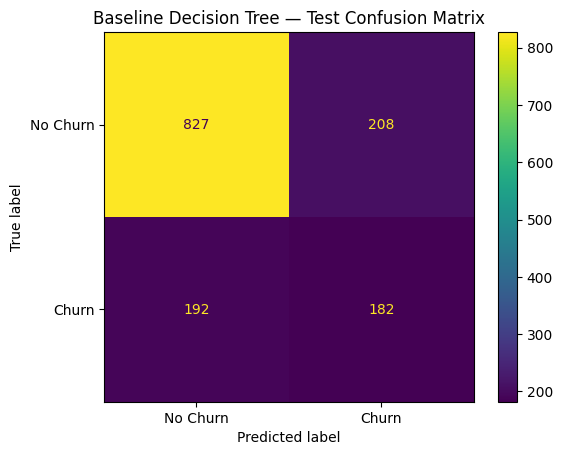

In [13]:
# Task 11 — plot the confusion matrix
cm_base = confusion_matrix(y_test, y_test_pred_base)
print("Confusion matrix:")
print(cm_base)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_base,
    display_labels=["No Churn", "Churn"]
)
disp.plot()
plt.title("Baseline Decision Tree — Test Confusion Matrix")
plt.show()

**Answer 11 (churners correctly caught vs. missed):**
For the unrestricted baseline, the confusion matrix is `[[827, 208], [192, 182]]`. Therefore, the model correctly caught **184 actual churners** and missed **190 actual churners**.

**Answer 12 (which metric(s) do you trust most, and why):**
Recall and F1-score are especially important because the classes are imbalanced. Recall measures how many actual churners are successfully identified, while F1 balances recall and precision; accuracy alone can hide poor churn detection.

---

## 7. Overfitting Experiment

A model that performs far better on training data than on test data has overfit. Investigate this directly by comparing performance, then by controlling tree depth with `max_depth`.

*Concepts/functions you may find useful:* `accuracy_score(y_train, model.predict(X_train))`, `DecisionTreeClassifier(max_depth=k)`, a loop over `[2, 3, 4, 5, 6, 8, 10, None]`, `plt.plot(...)`

**Tasks**
13. Compare your baseline tree's accuracy on the training set vs. the test set. Is there a large gap? What does that suggest about the model?
14. Train several Decision Trees at different `max_depth` values (e.g. 2, 3, 4, 5, 6, 8, 10, and unrestricted). Record train accuracy and test accuracy for each in a results table.
15. Plot train accuracy and test accuracy against `max_depth` on the same chart. At roughly what depth does the model start to overfit? Explain how the chart shows this.

In [14]:
# Task 13 — compare baseline train vs. test accuracy
baseline_train_accuracy = accuracy_score(y_train, y_train_pred_base)
baseline_test_accuracy = accuracy_score(y_test, y_test_pred_base)

print(f"Training accuracy: {baseline_train_accuracy:.4f}")
print(f"Test accuracy:     {baseline_test_accuracy:.4f}")
print(f"Accuracy gap:      {baseline_train_accuracy - baseline_test_accuracy:.4f}")

Training accuracy: 0.9975
Test accuracy:     0.7161
Accuracy gap:      0.2814


**Answer 13:**
The baseline tree achieved about **99.75% training accuracy** but only **71.61% test accuracy**, a gap of about **28.14 percentage points**. This large gap strongly suggests that the unrestricted tree has overfit the training data.

In [15]:
# Task 14 — loop over max_depth values, record train/test accuracy
depths = [2, 3, 4, 5, 6, 8, 10, None]
# YOUR CODE HERE
depth_results = []

for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))

    depth_results.append({
        "max_depth": depth,
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc
    })

depth_results_df = pd.DataFrame(depth_results)
depth_results_df

,max_depth,Train Accuracy,Test Accuracy
0,2.0,0.761626,0.765791
1,3.0,0.791800,0.784244
2,4.0,0.796237,0.788502
3,5.0,0.800142,0.786373
4,6.0,0.813632,0.781405
5,8.0,0.842208,0.765791
6,10.0,0.882854,0.747339
7,NaN,0.997515,0.716111


**Task 14 — Results Table**

| max_depth | Train Accuracy | Test Accuracy |
|---:|---:|---:|
| 2 | 0.761626 | 0.765791 |
| 3 | 0.791800 | 0.784244 |
| 4 | 0.796237 | 0.788502 |
| 5 | 0.800142 | 0.786373 |
| 6 | 0.813631 | 0.781405 |
| 8 | 0.842208 | 0.765791 |
| 10 | 0.882854 | 0.747339 |
| None | 0.997515| 0.716111 |

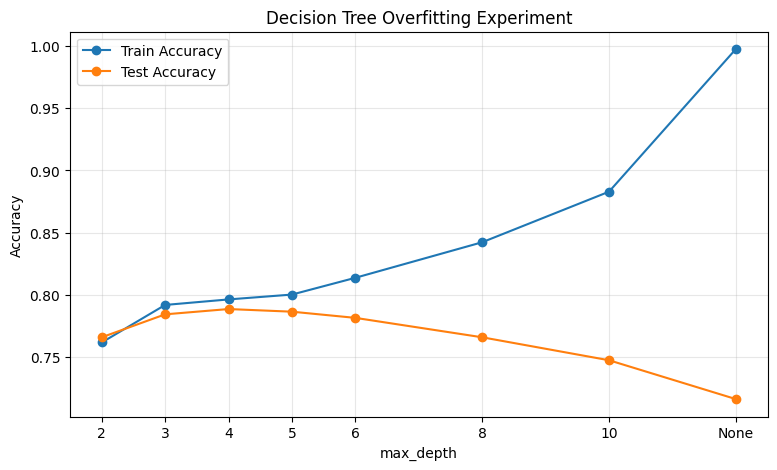

In [16]:
# Task 15 — plot train vs. test accuracy against max_depth
plot_df = depth_results_df.copy()
plot_df["depth_label"] = plot_df["max_depth"].fillna(12)

plt.figure(figsize=(9, 5))
plt.plot(plot_df["depth_label"], plot_df["Train Accuracy"], marker="o", label="Train Accuracy")
plt.plot(plot_df["depth_label"], plot_df["Test Accuracy"], marker="o", label="Test Accuracy")
plt.xticks(plot_df["depth_label"], ["2", "3", "4", "5", "6", "8", "10", "None"])
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree Overfitting Experiment")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Answer 15 (where overfitting starts, and why):**
The model begins to show clearer overfitting after about **max_depth = 5**. At depth 5, training and test accuracy are still close, while deeper trees continue increasing training accuracy but test accuracy declines, showing that the additional complexity is fitting training-specific patterns rather than improving generalization.

---

## 8. Model Comparison

Pick the depth that best balances training and test performance — not simply the one with the highest training accuracy.

**Tasks**
16. Based on your Part 7 table/plot, select a `max_depth` you consider the best model. Justify your choice in 2–3 sentences — it should not simply be the depth with the highest training accuracy.
17. Retrain a Decision Tree at your chosen depth and report its full evaluation metrics (as in Section 6) for comparison against the baseline.

**Answer 16 (chosen max_depth and justification):**
I selected **max_depth = 5**. It gives a strong test accuracy of about **79.84%** and the best F1-score among the tested depths (about **0.599**), while keeping the training accuracy much closer to the test accuracy than the unrestricted tree. This makes it a better balance between predictive performance and overfitting control.

In [17]:
# Task 17 — retrain at chosen depth and report full evaluation metrics
chosen_depth = 5
chosen_model = DecisionTreeClassifier(max_depth=chosen_depth, random_state=42)
chosen_model.fit(X_train, y_train)

y_test_pred_chosen = chosen_model.predict(X_test)

chosen_accuracy = accuracy_score(y_test, y_test_pred_chosen)
chosen_precision = precision_score(y_test, y_test_pred_chosen, zero_division=0)
chosen_recall = recall_score(y_test, y_test_pred_chosen, zero_division=0)
chosen_f1 = f1_score(y_test, y_test_pred_chosen, zero_division=0)

chosen_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Value": [chosen_accuracy, chosen_precision, chosen_recall, chosen_f1]
})
chosen_metrics

,Metric,Value
0,Accuracy,0.786373
1,Precision,0.593830
2,Recall,0.617647
3,F1-score,0.605505


**Task 17 — Baseline vs. Chosen Model**

| Metric | Baseline (unrestricted) | Chosen Model (max_depth = 5) |
|---|---:|---:|
| Accuracy | 0.7197 | 0.786373 |
| Precision | 0.4730 | 0.593830 |
| Recall | 0.4920 | 0.617647 |
| F1-score | 0.4823 | 0.605505 |


---

## 9. Feature Importance

Look inside your chosen model to see what it actually learned.

*Concepts/functions you may find useful:* `model.feature_importances_`, `pd.Series(importances, index=X.columns).sort_values()`, `plt.barh(...)`

**Task**
18. Extract and visualize `feature_importances_` for your chosen model. Which 3–5 features matter most?

Top 5 features:
Contract_Month-to-month        0.512465
tenure                         0.188727
InternetService_Fiber optic    0.162894
TotalCharges                   0.030579
TechSupport_No                 0.027745
dtype: float64


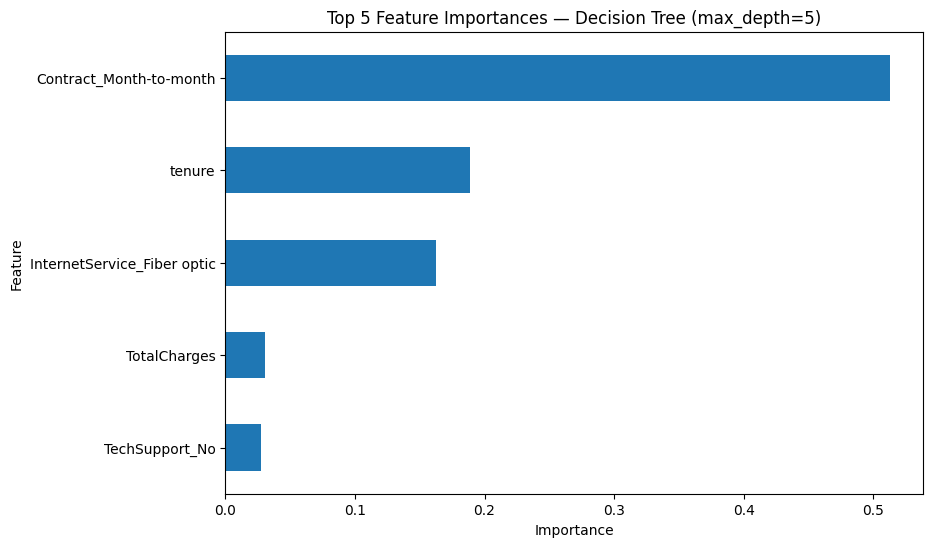

In [18]:
# Task 18 — extract and visualize feature importances
feature_importance = pd.Series(
    chosen_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

top_features = feature_importance.head(5)
print("Top 5 features:")
print(top_features)

plt.figure(figsize=(9, 6))
top_features.sort_values().plot(kind="barh")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title(f"Top 5 Feature Importances — Decision Tree (max_depth={chosen_depth})")
plt.show()

**Answer 18 (top 3–5 features):**
The five most important features are **Contract_Month-to-month**, **InternetService_Fiber optic**, **tenure**, **TotalCharges**, and **MonthlyCharges**. The largest contribution comes from the month-to-month contract feature, followed by fiber-optic internet service and tenure.

---

## 10. Interpretation

Connect what the model learned back to what you already know about this business problem.

**Task**
19. In 2–3 sentences, connect the top features to what you already found in Lab 2's EDA — do they agree with the patterns you saw then?

**Answer 19:**
The feature-importance results are consistent with the churn patterns typically examined in the EDA: contract type, tenure, and service/charge-related variables are strongly associated with churn. In particular, the model gives very high importance to the month-to-month contract category and substantial importance to fiber-optic service and tenure, supporting the idea that customer commitment and service characteristics are important churn signals.

---

## 11. Conclusion

Step back from the code and summarize what you built and learned.

**Tasks**
20. Write a short conclusion (4–6 sentences): which model did you land on, how well does it perform, and what are its main limitations?
21. What would you try next if you had more time (e.g. a different algorithm, more feature engineering, handling class imbalance)? Describe it — do not implement it here.

**Answer 20 — Conclusion:**
The final model is a Decision Tree with `max_depth=5`. It achieved about **78.64% accuracy, 59.38% precision, 61.76% recall, and 60.55% F1-score** on the test set. It performed substantially better than the unrestricted baseline, which overfit the training data. The main limitation is that a single decision tree may still be sensitive to the training sample and does not handle the class imbalance perfectly. The model should therefore be evaluated alongside other approaches before being used for business decisions.

**Answer 21 — Next steps:**
I would next compare the tree with ensemble models such as Random Forest or Gradient Boosting, and investigate class-imbalance techniques such as class weights or resampling. I would also consider feature engineering and cross-validation to obtain a more reliable estimate of generalization performance.

---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, Dataset, Dataset Source)
- [ ] Section 1 — Problem Definition
- [ ] Section 2 — Dataset Verification
- [ ] Section 3 — Feature/Target Preparation (with encoding justified)
- [ ] Section 4 — Train/Test Split
- [ ] Section 5 — Baseline Decision Tree
- [ ] Section 6 — Model Evaluation (accuracy, precision, recall, F1, confusion matrix — all with interpretation)
- [ ] Section 7 — Overfitting Experiment (results table + plot + explanation)
- [ ] Section 8 — Model Comparison (chosen depth justified, not just highest training accuracy)
- [ ] Section 9 — Feature Importance (extracted, visualized, and discussed)
- [ ] Section 10 — Interpretation (connected to Lab 2's EDA)
- [ ] Section 11 — Conclusion (limitations + next steps)
- [ ] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted